# Corales de Panamá y eventos de El Niño: un análisis con datos abiertos
## Dataset de corales
### Limpieza de datos

#### Se limpian los registros de corales duros (Scleractinia) de Panamá descargados de GBIF. El archivo original se conserva sin modificar y el resultado se guarda en `datos/limpios/`
Por Angela Pérez

In [2]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

## 1. Cargamos los datos originales de GBIF
Fuente: GBIF, descarga 0041553-260928105237408 (Catalogue of Life). El archivo está separado por tabulaciones.

In [3]:
corales = pd.read_csv(
    "../datos/originales/0041553-260928105237408.csv",
    sep="\t",
    low_memory=False,
)
corales.shape

(14395, 50)

## 2. Antes de la limpieza

Estaremos revisando cúantas filas y columnas tiene el dataset de corales, qué tipo de datos tiene cada columna como referencias y tomar decisiones para la limpieza de estos datos.

Tamaños y tipos:

In [4]:
print("Filas y columnas:", corales.shape)
corales.info()

Filas y columnas: (14395, 50)
<class 'pandas.DataFrame'>
RangeIndex: 14395 entries, 0 to 14394
Data columns (total 50 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   gbifID                            14395 non-null  int64  
 1   datasetKey                        14395 non-null  str    
 2   occurrenceID                      14395 non-null  str    
 3   kingdom                           14395 non-null  str    
 4   phylum                            14395 non-null  str    
 5   class                             14395 non-null  str    
 6   order                             14395 non-null  str    
 7   family                            14260 non-null  str    
 8   genus                             14121 non-null  str    
 9   species                           12885 non-null  str    
 10  infraspecificEpithet              40 non-null     str    
 11  taxonRank                         14395 non-null

Faltantes por columna:

In [5]:
faltantes_antes = corales.isna().sum().sort_values(ascending=False)
print(faltantes_antes.to_string())

elevationAccuracy                   14395
elevation                           14395
establishmentMeans                  14395
infraspecificEpithet                14355
recordNumber                        14342
typeStatus                          14052
dateIdentified                      13578
mediaType                           13573
coordinatePrecision                 13398
rightsHolder                        12929
stateProvince                       12526
identifiedBy                        11324
individualCount                     11317
locality                            10477
recordedBy                           9751
coordinateUncertaintyInMeters        8580
verbatimScientificNameAuthorship     6165
catalogNumber                        5843
depthAccuracy                        4701
depth                                4654
day                                  3317
month                                3008
eventDate                            1932
year                              

Tipos de registro en nuestro dataset

`basisOfRecord` es un término estándar del formato Darwin Core que indica el origen físico o la naturaleza de cómo se obtuvo ese registro de un ser vivo 

In [6]:
corales["basisOfRecord"].value_counts()

basisOfRecord
HUMAN_OBSERVATION      9802
PRESERVED_SPECIMEN     3347
MATERIAL_CITATION       863
FOSSIL_SPECIMEN         231
MACHINE_OBSERVATION      77
MATERIAL_SAMPLE          73
LIVING_SPECIMEN           2
Name: count, dtype: int64

Explorando para mas detalle de Material Citation ya que no es claro de primera instancia que significa este tipo de datos

In [7]:
corales.groupby("institutionCode")["datasetKey"].unique()

institutionCode
AGRRA                                                    [ec245bc1-4812-438d-8d07-5d74ad0bd496]
AMNH                                                     [87dbda50-7d25-47e9-a7df-e4d4951fe9e6]
ANSP                                                     [ec3805da-46a8-433b-bebc-20fed11f9e1e]
BPBM                                          [50743314-a455-4f64-b5d5-8a4e816aeec6, b929f23...
CAS                                                      [44bcde48-ac71-46f2-bf73-24fc3c008b6c]
CASG                                                     [5e848873-567f-42dd-8a29-88056b9b33a4]
CMN                                                      [b50dfef4-3f34-4829-9d6e-edd5fcdb2b29]
FMNH                                                     [005eb8d8-ed94-41be-89cf-e3115a9058e4]
HEX                                                      [adb92d68-aaff-47ba-b197-d3d26f72f728]
LACM                                                     [f0a7ca6e-8da6-4629-97bd-0368705a4d6b]
MCZ                     

In [8]:
corales[corales["basisOfRecord"] == "MATERIAL_CITATION"]["institutionCode"].value_counts()

institutionCode
PBDB    863
Name: count, dtype: int64

**Observaciones hasta ahora:**
- El dataset tiene 14,395 registros y 50 columnas.
- Varias columnas están casi vacías, como `establishmentMeans` (100 % ) y `stateProvince` (87 %).
- Hay 231 registros fósiles y 863 citas de fósiles (PBDB) que no corresponden a corales vivos. (Estos corales por ser fósiles no les afecta la temperatura)
- 1,355 registros no tienen coordenadas y 1,510 no tienen especie. 

## 3. Eliminar columnas innecesarias para nuestro análisis

Se eliminan 18 columnas que están casi vacías, que no se necesitan para el análisis
o que contienen nombres de personas (por privacidad).
Se conserva `depth` (profundidad), porque tiene el 68 % de los datos y sirve para separar
corales someros(poco profundos) y profundos.

Para decidir qué columnas eliminar se usaron dos criterios: (1) el porcentaje de valores faltantes, revisado en `faltantes_antes` (un número alto indica una columna muy vacía), y (2) si la columna es necesaria para responder las preguntas del proyecto. Por eso se eliminan algunas columnas que no están tan vacías, como verbatimScientificNameAuthorship, y se conserva depth, aunque le falte el 32 % de los datos.

In [9]:
porcentaje_faltantes = (faltantes_antes / len(corales) * 100).round(1)
print(porcentaje_faltantes.to_string())

elevationAccuracy                   100.0
elevation                           100.0
establishmentMeans                  100.0
infraspecificEpithet                 99.7
recordNumber                         99.6
typeStatus                           97.6
dateIdentified                       94.3
mediaType                            94.3
coordinatePrecision                  93.1
rightsHolder                         89.8
stateProvince                        87.0
identifiedBy                         78.7
individualCount                      78.6
locality                             72.8
recordedBy                           67.7
coordinateUncertaintyInMeters        59.6
verbatimScientificNameAuthorship     42.8
catalogNumber                        40.6
depthAccuracy                        32.7
depth                                32.3
day                                  23.0
month                                20.9
eventDate                            13.4
year                              

In [10]:
columnas_a_borrar = [
    "infraspecificEpithet", "verbatimScientificNameAuthorship", "locality",
    "stateProvince", "individualCount", "coordinateUncertaintyInMeters",
    "coordinatePrecision", "elevation", "elevationAccuracy", "depthAccuracy",
    "catalogNumber", "recordNumber", "identifiedBy", "dateIdentified",
    "recordedBy", "typeStatus", "establishmentMeans", "mediaType",
]

corales_limpio = corales.drop(columns=columnas_a_borrar)
corales_limpio.shape

(14395, 32)

## 4. Excluir registros que no son corales vivos en su ambiente

Se excluyen 1,096 registros, porque no se pueden comparar con la temperatura actual del mar:
- 231 fósiles (`FOSSIL_SPECIMEN`)
- 863 fósiles citados en publicaciones (`MATERIAL_CITATION`, todos de PBDB)
- 2 corales en cautiverio (`LIVING_SPECIMEN`)

In [11]:
tipos_validos = ["HUMAN_OBSERVATION", "PRESERVED_SPECIMEN",
                 "MACHINE_OBSERVATION", "MATERIAL_SAMPLE"]

corales_limpio = corales_limpio[corales_limpio["basisOfRecord"].isin(tipos_validos)].copy()
corales_limpio.shape

(13299, 32)

## 5. Renombrar columnas a snake_case

Los nombres de las columnas vienen en formato camelCase (por ejemplo, `decimalLatitude`).
Se convierten a snake_case (minúsculas y palabras separadas por guion bajo), y las columnas
principales se renombran en español para que sean más fáciles de leer.

In [12]:
nombres_nuevos = []                         # una lista vacía

for columna in corales_limpio.columns:
    con_guiones = re.sub(r"([a-z0-9])([A-Z])", r"\1_\2", columna) #busca patrones y pone los guiones
    en_minusculas = con_guiones.lower()             #pasa a minúsculas
    nombres_nuevos.append(en_minusculas)            #la agrega a la lista

corales_limpio.columns = nombres_nuevos           #reemplazamos los nombres
corales_limpio.columns

Index(['gbif_id', 'dataset_key', 'occurrence_id', 'kingdom', 'phylum', 'class',
       'order', 'family', 'genus', 'species', 'taxon_rank', 'scientific_name',
       'verbatim_scientific_name', 'country_code', 'occurrence_status',
       'publishing_org_key', 'decimal_latitude', 'decimal_longitude', 'depth',
       'event_date', 'day', 'month', 'year', 'taxon_key', 'species_key',
       'basis_of_record', 'institution_code', 'collection_code', 'license',
       'rights_holder', 'last_interpreted', 'issue'],
      dtype='str')

Cambiamos los nombres de las columnas que más se va a usar a español. Se tradujeron al español solo las columnas usadas en el análisis (latitud, longitud, profundidad_m, anio). Las demás conservan el nombre original de GBIF en snake_case, para facilitar la comparación con la fuente

In [13]:
corales_limpio = corales_limpio.rename(columns={
    "decimal_latitude": "latitud",
    "decimal_longitude": "longitud",
    "depth": "profundidad_m",
    "year": "anio",
})

corales_limpio.columns

Index(['gbif_id', 'dataset_key', 'occurrence_id', 'kingdom', 'phylum', 'class',
       'order', 'family', 'genus', 'species', 'taxon_rank', 'scientific_name',
       'verbatim_scientific_name', 'country_code', 'occurrence_status',
       'publishing_org_key', 'latitud', 'longitud', 'profundidad_m',
       'event_date', 'day', 'month', 'anio', 'taxon_key', 'species_key',
       'basis_of_record', 'institution_code', 'collection_code', 'license',
       'rights_holder', 'last_interpreted', 'issue'],
      dtype='str')

Verificación de fechas

In [14]:
corales_limpio[["event_date", "anio", "month", "day"]].head(10)

,event_date,anio,month,day
0,2026-01-16T09:50,2026.0,1.0,16.0
1,2026-01-14T19:48,2026.0,1.0,14.0
2,2026-01-14T09:58,2026.0,1.0,14.0
3,2026-01-14T19:36,2026.0,1.0,14.0
4,2026-01-14T19:24,2026.0,1.0,14.0
5,2026-01-14T09:46,2026.0,1.0,14.0
6,2026-01-14T19:48,2026.0,1.0,14.0
7,2026-01-16T09:35,2026.0,1.0,16.0
8,2026-01-16T09:46,2026.0,1.0,16.0
9,2026-01-16T09:48,2026.0,1.0,16.0


In [15]:
corales_limpio[["event_date", "anio"]].dtypes

event_date        str
anio          float64
dtype: object

In [16]:
corales_limpio["anio"].isna().sum()

np.int64(923)

## 6. Tipos de datos correctos

- `event_date` viene como texto; se convierte a fecha.
- `anio`, `month` y `day` vienen como decimales (2026.0) porque tienen valores vacíos;
  se convierten a enteros que aceptan vacíos (`Int64`).
- 923 registros no tienen año: se conservan para el mapa y el conteo de especies,
  pero no se usarán en el cruce con la temperatura.

Convertir fechas

In [17]:
corales_limpio["fecha"] = pd.to_datetime(
    corales_limpio["event_date"],
    errors="coerce",
    format="ISO8601",
    utc=True,
)

In [18]:
corales_limpio[["event_date", "fecha"]].head()

,event_date,fecha
0,2026-01-16T09:50,2026-01-16 09:50:00+00:00
1,2026-01-14T19:48,2026-01-14 19:48:00+00:00
2,2026-01-14T09:58,2026-01-14 09:58:00+00:00
3,2026-01-14T19:36,2026-01-14 19:36:00+00:00
4,2026-01-14T19:24,2026-01-14 19:24:00+00:00


In [19]:
corales_limpio["fecha"].dtype

datetime64[us, UTC]

Revisamos cuántas fechas no se pudieron leer

In [20]:
print("Sin fecha en el original:", corales_limpio["event_date"].isna().sum())
print("Sin fecha después de convertir:", corales_limpio["fecha"].isna().sum())

Sin fecha en el original: 923
Sin fecha después de convertir: 932


In [21]:
fechas_raras = corales_limpio[
    corales_limpio["fecha"].isna() & corales_limpio["event_date"].notna()
]
fechas_raras[["event_date", "anio", "month", "day"]]

,event_date,anio,month,day
696,1963-08-01/1963-08-31,1963.0,8.0,NaN
704,1872-07-01/1872-07-23,1872.0,7.0,NaN
728,1975-02-17/1975-02-19,1975.0,2.0,NaN
12409,1979-06-01/1979-06-30,1979.0,6.0,NaN
12908,1987-09-10/1987-10-20,1987.0,NaN,NaN
13259,1986-09-04/1986-09-30,1986.0,9.0,NaN
13643,1987-01-19/1987-02-03,1987.0,NaN,NaN
13731,1988-07-09/1988-07-15,1988.0,7.0,NaN
14374,1975-02-17/1975-02-19,1975.0,2.0,NaN


Pasamos años, mes y día a numeros enteros

In [22]:
corales_limpio[["anio", "month", "day"]] = corales_limpio[["anio", "month", "day"]].astype("Int64")
corales_limpio[["anio", "month", "day"]].head()

,anio,month,day
0,2026,1,16
1,2026,1,14
2,2026,1,14
3,2026,1,14
4,2026,1,14


## 7. Tratamiento de faltantes

Después de eliminar columnas y registros, se vuelven a contar los valores faltantes
de cada columna, en cantidad y en porcentaje.

Para cada columna con faltantes se decide si los registros se **eliminan**,
se **imputan** (se rellenan con la media, la mediana o la moda) o se **marcan como "sin dato"**,
y se justifica la decisión.

In [23]:
faltantes = corales_limpio.isna().sum()
porcentaje = (faltantes / len(corales_limpio) * 100).round(1)

tabla_faltantes = pd.DataFrame({"faltantes": faltantes, "porcentaje": porcentaje})
tabla_faltantes[tabla_faltantes["faltantes"] > 0].sort_values("faltantes", ascending=False)

,faltantes,porcentaje
rights_holder,11834,89.0
profundidad_m,3558,26.8
day,2292,17.2
month,1983,14.9
species,1232,9.3
species_key,1232,9.3
longitud,1189,8.9
latitud,1189,8.9
fecha,932,7.0
event_date,923,6.9


In [24]:
# Eliminar rights_holder: 89 % vacía y no se usa en el análisis
corales_limpio = corales_limpio.drop(columns=["rights_holder"])

# Marcar como "sin dato" las columnas de texto con pocos vacíos
corales_limpio["institution_code"] = corales_limpio["institution_code"].fillna("sin dato")
corales_limpio["collection_code"] = corales_limpio["collection_code"].fillna("sin dato")

### Decisiones sobre los faltantes

| Columna | Faltantes | Decisión | Justificación |
|---|---|---|---|
| `rights_holder` | 89 % | Eliminar la columna | Casi vacía y no se usa en el análisis |
| `profundidad_m` | 26.8 % | Conservar; marcar la zona como "sin dato" | Inventar una profundidad podría clasificar mal un coral |
| `day`, `month` | 17.2 % y 14.9 % | Conservar | El análisis es por año, no por día ni mes |
| `species`, `species_key` | 9.3 % | Conservar | Son corales identificados solo hasta género o familia; sirven para el mapa |
| `latitud`, `longitud` | 8.9 % | Conservar; costa "sin dato" | Inventar coordenadas pondría corales en lugares falsos |
| `anio`, `event_date`, `fecha` | 6.9 % a 7.0 % | Conservar; no se usan en el cruce con la temperatura | Sirven para el mapa y el conteo de especies |
| `institution_code`, `collection_code` | 1.7 % y 2.2 % | Marcar como "sin dato" | Son categorías; un texto claro es mejor que un vacío |
| `genus`, `family`, `verbatim_scientific_name`, `issue` | menos de 1 % | Conservar | Son muy pocos y no afectan el análisis |

In [25]:
corales_limpio.shape

(13299, 32)

## 8. Tratamiento de atípicos: profundidad

La profundidad tiene valores extremos: la mediana es de 4.5 m, pero el máximo llega a 3,950 m.
Estos valores no son errores, sino corales de aguas profundas (por ejemplo, *Dasmosmilia lymani*
y *Fungiacyathus symmetricus*), que no forman arrecifes y no dependen de la temperatura de la superficie.

No se eliminan, pero se marcan en una columna nueva, `zona`:
- **somera**: hasta 50 m de profundidad
- **profunda**: más de 50 m
- **sin dato**: registros sin profundidad anotada

In [26]:
corales_limpio["profundidad_m"].describe()

count    9741.000000
mean       21.720755
std       162.768019
min         0.000000
25%         1.550000
50%         4.500000
75%         8.000000
max      3950.000000
Name: profundidad_m, dtype: float64

Creamos columna: zona

In [27]:
corales_limpio["zona"] = "sin dato"
corales_limpio.loc[corales_limpio["profundidad_m"] <= 50, "zona"] = "somera"
corales_limpio.loc[corales_limpio["profundidad_m"] > 50, "zona"] = "profunda"

corales_limpio["zona"].value_counts()

zona
somera      9455
sin dato    3558
profunda     286
Name: count, dtype: int64

Contamos los datos. Hay corales profundos que no tenian institucion anatoda, por lo que no aparecia en la cuenta antes pero ahora si al contarlos especificamente por la profundidad solamente.

## 9. Clasificación por costa

Para unir los corales con la temperatura, cada registro se clasifica como "Caribe" o "Pacífico"
según sus coordenadas. Como Panamá tiene forma de "S", se usan tres zonas de oeste a este,
cada una con su propio límite de latitud. Los registros sin coordenadas quedan como "sin dato".
La clasificación se verifica con un mapa.

### Reglas para clasificar la costa

Como Panamá tiene forma de "S", una sola latitud no alcanza para separar el Caribe del Pacífico.
Por eso el país se divide en tres zonas de oeste a este, y en cada una se define una latitud límite:
los registros al **norte** de ese límite se clasifican como **Caribe** y los demás como **Pacífico**.
Los registros sin coordenadas quedan como **"sin dato"**.

Reglas de clasificacion:

| Zona | Rango de longitud | Es Caribe si la latitud es mayor que… | Referencia en el Caribe | Referencia en el Pacífico |
|---|---|---|---|---|
| Oeste | menor que −80.5° | 8.7° | Bocas del Toro (~9.3°) | Golfo de Chiriquí (~8.3°) |
| Centro | entre −80.5° y −78.5° | 9.1° | Cerca de Colón (9.14°) | Coronado (8.52°) |
| Este | mayor que −78.5° | 8.6° | Puerto Obaldía (~8.7°) | Golfo de San Miguel (~8.4°) |

Los límites se definieron de forma aproximada a partir de la ubicación de las costas en cada zona,
y se comprobaron con coordenadas reales en Google Maps. Por ejemplo, en la zona centro, un punto
del lado del Caribe cerca de Colón tiene latitud 9.14 y la costa de Coronado (Pacífico) tiene 8.52,
por lo que el límite de 9.1 queda entre ambas costas. Además, la clasificación se verifica con un mapa de los registros.

In [28]:
corales_limpio["costa"] = "sin dato"

tiene_coordenadas = corales_limpio["latitud"].notna()
corales_limpio.loc[tiene_coordenadas, "costa"] = "Pacífico"

es_caribe = (
    ((corales_limpio["longitud"] < -80.5) & (corales_limpio["latitud"] > 8.7))
    | ((corales_limpio["longitud"].between(-80.5, -78.5)) & (corales_limpio["latitud"] > 9.1))
    | ((corales_limpio["longitud"] > -78.5) & (corales_limpio["latitud"] > 8.6))
)
corales_limpio.loc[es_caribe, "costa"] = "Caribe"

corales_limpio["costa"].value_counts()

costa
Caribe      11365
sin dato     1189
Pacífico      745
Name: count, dtype: int64

In [29]:
pd.crosstab(corales_limpio["institution_code"], corales_limpio["costa"])

costa,Caribe,Pacífico,sin dato
institution_code,,,
AGRRA,4149,0,0
AMNH,0,5,1
BPBM,0,0,4
CAS,1,12,0
CMN,0,0,1
FMNH,0,3,0
HEX,62,71,0
MCZ,113,21,1
MNHN,0,0,2


**Observación:** el 94 % de los registros con ubicación son del Caribe. Esto refleja un mayor
esfuerzo de muestreo en esa costa (por ejemplo, el programa AGRRA trabaja solo en el Caribe)
y no hay necesariamente una mayor cantidad de corales.

Mapa para verificar

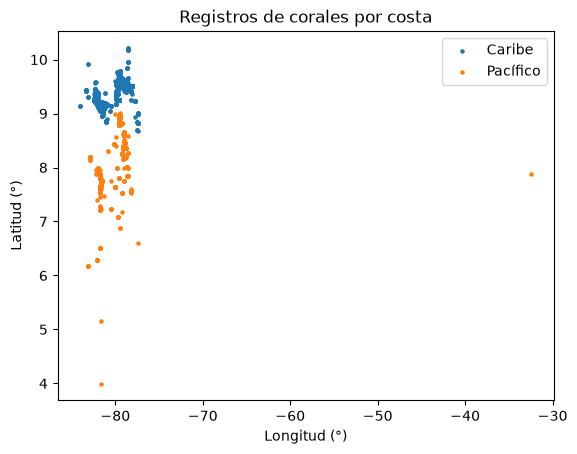

In [30]:
con_costa = corales_limpio[corales_limpio["costa"] != "sin dato"]

for costa, grupo in con_costa.groupby("costa"):
    plt.scatter(grupo["longitud"], grupo["latitud"], s=5, label=costa)

plt.title("Registros de corales por costa")
plt.xlabel("Longitud (°)")
plt.ylabel("Latitud (°)")
plt.legend()
plt.show()

Aqui podemos observar unos puntos atipicos, puede que sea parte de un registro que no este correcto o que se haya escrito mal

Buscamos los puntos que estan al este de Panamá (longitud mayor que −77) o muy al sur (latitud menor que 5.5).

In [31]:
raros = corales_limpio[(corales_limpio["longitud"] > -77) | (corales_limpio["latitud"] < 5.5)]
raros[["institution_code", "species", "latitud", "longitud", "anio", "basis_of_record"]]

,institution_code,species,latitud,longitud,anio,basis_of_record
1649,SIO,NaN,7.87058,-32.46250,1970,PRESERVED_SPECIMEN
1671,SIO,NaN,5.16333,-81.68667,1981,PRESERVED_SPECIMEN
11499,MCZ,Astrangia dentata,3.99444,-81.58333,<NA>,PRESERVED_SPECIMEN


De los 3 puntos: el registro 1649 está en el océano Atlántico (probablemente un error de escritura) y el 11499 está en la isla Malpelo (Colombia); ambos se marcan como “sin dato”. El 1671 es un coral de aguas profundas (3,950 m) al sur de Panamá, dentro de su zona marítima, así que se conserva como Pacífico. Por eso el límite de latitud es 4.5 y no 5.5.

In [32]:
fuera_de_panama = (corales_limpio["longitud"] > -77) | (corales_limpio["latitud"] < 4.5)
corales_limpio.loc[fuera_de_panama, "costa"] = "sin dato"

corales_limpio["costa"].value_counts()

costa
Caribe      11365
sin dato     1191
Pacífico      743
Name: count, dtype: int64

Son atípicos de ubicación: sus coordenadas no corresponden a Panamá. La decisión más honesta es no inventar dónde están, sino marcarlos como “sin dato” en la costa, igual que los que no tienen coordenadas.

Correccion de mapa

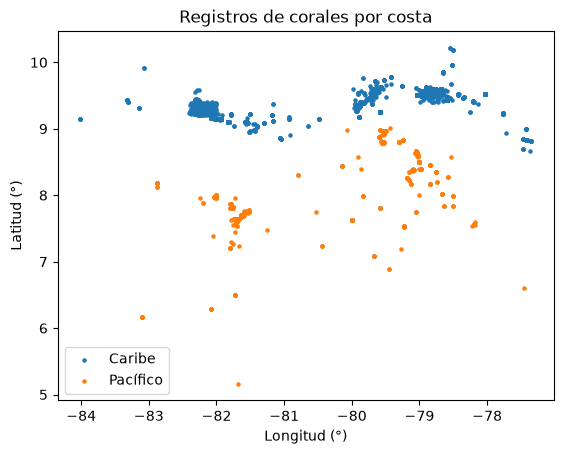

In [33]:
con_costa = corales_limpio[corales_limpio["costa"] != "sin dato"]

for costa, grupo in con_costa.groupby("costa"):
    plt.scatter(grupo["longitud"], grupo["latitud"], s=5, label=costa)

plt.title("Registros de corales por costa")
plt.xlabel("Longitud (°)")
plt.ylabel("Latitud (°)")
plt.legend()
plt.show()

## 10. Duplicados

Un registro se considera posible duplicado si coincide con otro en especie, coordenadas,
profundidad y fecha. Sin embargo, muchos de estos casos no son duplicados reales, sino colonias
distintas registradas en un mismo monitoreo (por ejemplo, el programa AGRRA anota cada colonia
de coral por separado, aunque estén en el mismo lugar y el mismo día).

Por eso, solo se consideran **duplicados reales** los registros que cumplen tres condiciones:
1. Coinciden en especie, coordenadas, profundidad y fecha.
2. Tienen especie, coordenadas y fecha anotadas (si faltan datos, no se puede saber si es el mismo coral).
3. Fueron publicados por **instituciones distintas**, lo que indica que el mismo coral se publicó dos veces.

De cada duplicado real se conserva la versión de la primera institución y se eliminan las demás.

In [34]:
columnas_clave = ["species", "latitud", "longitud", "profundidad_m", "event_date"]

parecidos = corales_limpio[corales_limpio.duplicated(subset=columnas_clave, keep=False)]
print("Registros que se parecen a otro:", len(parecidos))

grupos = parecidos.groupby(columnas_clave, dropna=False)["institution_code"].nunique()
print("Grupos con más de una institución:", (grupos > 1).sum())

Registros que se parecen a otro: 10063
Grupos con más de una institución: 174


In [35]:
# 1. Para cada grupo de registros "iguales": cuántas instituciones tiene y cuál aparece primero
instituciones_en_grupo = corales_limpio.groupby(columnas_clave, dropna=False)["institution_code"].transform("nunique")
primera_institucion = corales_limpio.groupby(columnas_clave, dropna=False)["institution_code"].transform("first")

# 2. Solo cuentan los registros con especie, coordenadas y fecha anotadas
datos_completos = corales_limpio[["species", "latitud", "longitud", "event_date"]].notna().all(axis=1)

# 3. Es copia si: el grupo tiene varias instituciones, los datos están completos
#    y el registro NO es de la primera institución del grupo
es_copia = (instituciones_en_grupo > 1) & datos_completos & (corales_limpio["institution_code"] != primera_institucion)

print("Copias encontradas:", es_copia.sum())

Copias encontradas: 39


De donde vienen los duplicados

In [36]:
corales_limpio.loc[es_copia, "institution_code"].value_counts()

institution_code
USNM    38
NIWA     1
Name: count, dtype: int64

Eliminamos las copias

In [37]:
corales_limpio = corales_limpio[~es_copia].copy()
corales_limpio.shape

(13260, 34)

- Las copias eliminadas vienen principalmente del Smithsonian (USNM, 38) y de NIWA (1).
  Probablemente son registros de museo que también aparecen en compilaciones de otras
  instituciones. Como ambas versiones tienen la misma especie, ubicación, profundidad y fecha,
  conservar una u otra no cambia el análisis.

## 11. Perfil final (después de la limpieza)

Se compara el dataset antes y después de la limpieza: cantidad de filas, columnas y celdas vacías,
tipos de datos y distribución de los registros por costa y zona.

In [38]:
comparacion = pd.DataFrame({
    "Antes": [len(corales), corales.shape[1], corales.isna().sum().sum()],
    "Después": [len(corales_limpio), corales_limpio.shape[1], corales_limpio.isna().sum().sum()],
}, index=["Filas", "Columnas", "Celdas vacías"])

comparacion

,Antes,Después
Filas,14395,13260
Columnas,50,34
Celdas vacías,241633,15673


tipo de datos finales

In [39]:
corales_limpio.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
Index: 13260 entries, 0 to 14394
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype              
---  ------                    --------------  -----              
 0   gbif_id                   13260 non-null  int64              
 1   dataset_key               13260 non-null  str                
 2   occurrence_id             13260 non-null  str                
 3   kingdom                   13260 non-null  str                
 4   phylum                    13260 non-null  str                
 5   class                     13260 non-null  str                
 6   order                     13260 non-null  str                
 7   family                    13196 non-null  str                
 8   genus                     13140 non-null  str                
 9   species                   12028 non-null  str                
 10  taxon_rank                13260 non-null  str                
 11  scientific_name           13260

In [40]:
print(corales_limpio["costa"].value_counts(), "\n")
print(corales_limpio["zona"].value_counts())

costa
Caribe      11339
sin dato     1191
Pacífico      730
Name: count, dtype: int64 

zona
somera      9452
sin dato    3558
profunda     250
Name: count, dtype: int64


## 12. Bitácora de limpieza

| Columna | Justificación |
|---|---|
| 18 columnas (`infraspecificEpithet`, `locality`, `stateProvince`, `individualCount`, `coordinateUncertaintyInMeters`, `coordinatePrecision`, `elevation`, `elevationAccuracy`, `depthAccuracy`, `catalogNumber`, `recordNumber`, `identifiedBy`, `dateIdentified`, `recordedBy`, `typeStatus`, `establishmentMeans`, `mediaType`, `verbatimScientificNameAuthorship`) | Eliminadas: casi vacías (hasta 100 %), no necesarias para el análisis o con nombres de personas (privacidad). |
| `rights_holder` | Eliminada: 89 % vacía y no se usa en el análisis. |
| `basisOfRecord` | Se excluyeron 1,096 registros que no son corales vivos en su ambiente: 231 fósiles, 863 fósiles citados en publicaciones (PBDB) y 2 en cautiverio. |
| Todas las columnas | Nombres convertidos de camelCase a snake_case; las principales se tradujeron al español (`latitud`, `longitud`, `profundidad_m`, `anio`). |
| `event_date` → `fecha` | Convertida a fecha (formato ISO 8601, en UTC). 9 registros con un rango de fechas quedaron sin fecha, pero conservan el año. |
| `anio`, `month`, `day` | Convertidas de decimal a entero (`Int64`), que acepta valores vacíos. |
| `profundidad_m` | 26.8 % vacía: se conserva sin imputar, para no clasificar mal un coral. Valores atípicos (hasta 3,950 m) corresponden a corales de aguas profundas: no se eliminan, se marcan en la columna `zona`. |
| `zona` | Nueva: "somera" (≤ 50 m), "profunda" (> 50 m) o "sin dato" (sin profundidad). |
| `latitud`, `longitud` | 8.9 % vacías: se conservan sin imputar, para no inventar ubicaciones. Se marcaron como "sin dato" 2 registros con coordenadas fuera de Panamá (uno en el Atlántico y uno en la isla Malpelo, Colombia). |
| `costa` | Nueva: "Caribe" o "Pacífico" según las coordenadas, con límites por zona del país verificados en un mapa; "sin dato" si no hay coordenadas válidas. |
| `species`, `anio` | 9.3 % y 6.9 % vacías: se conservan, porque sirven para el mapa y el conteo de registros. Los registros sin año no se usan en el cruce con la temperatura. |
| `institution_code`, `collection_code` | Vacíos marcados como "sin dato". |
| Duplicados | Se eliminaron 39 duplicados reales: registros con la misma especie, ubicación, profundidad y fecha, publicados por más de una institución. Se conservaron los registros repetidos de una misma institución, porque corresponden a colonias distintas en monitoreos. |

## 13. Guardar los datos limpios

El resultado se guarda en `datos/limpios/corales_limpio.csv`. El archivo original no se modifica.

In [41]:
os.makedirs("../datos/limpios", exist_ok=True)
corales_limpio.to_csv("../datos/limpios/corales_limpio.csv", index=False)
print("Archivo guardado:", corales_limpio.shape)

Archivo guardado: (13260, 34)
